# Fitting real Gaia DR4 astrometry and RVs: Gaia-4b

Gaia-4b is a massive planet on a 1.6 yr orbit around a 0.64 $M_\odot$ star, found as a Gaia astrometric candidate and confirmed with RVs (Stefansson et al. 2025). Its Gaia DR4 epoch astrometry was among the data pre-released in June 2026. This notebook shows how real epoch astrometry and RVs are passed to gaiamockplus. It
1. downloads the DR4 pre-release epoch astrometry and converts it to the inputs gaiamockplus needs (one along-scan measurement per field-of-view transit),
2. searches the astrometry alone for planets,
3. loads RVs from four instruments (`data/Gaia4_RVs_Barbato26.csv`, Barbato et al. 2026),
4. fits the astrometry and RVs jointly and plots the best fit, and
5. samples the posterior with MCMC ([emcee](https://emcee.readthedocs.io)) and shows a corner plot.

It needs `gaiamockplus`, `emcee`, `corner` and `pandas`. The MCMC takes about 2.5 minutes.

In [1]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(1)            # random numbers for the MCMC starting points (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun
DATA_DIR = os.path.join('..', 'data')     # the repository's data folder

m_star = 0.644                            # stellar mass in Msun (Stefansson et al. 2025)
source_id = 1457486023639239296           # Gaia-4

## 1. The DR4 epoch astrometry

### Download

The pre-release contains the epoch astrometry of 12 sources, as a VOTable with one row per field-of-view transit. A copy of the zip file (626 kB) is included in the repository's `data` folder; it is downloaded from the Gaia archive only if it is missing, and read directly from the zip file.

In [2]:
url = 'https://anonftp.cosmos.esa.int/pub/GAIA_PUBLIC_DATA/Gaia_DR4/dr4-prerelease/gaia-dr4-prerelease-epoch-astrometry_2026-06-26.zip'
zip_path = os.path.join(DATA_DIR, os.path.basename(url))
if not os.path.isfile(zip_path):
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path) as zf:
    xml_name = [name for name in zf.namelist() if name.endswith('.xml')][0]
    with zf.open(xml_name) as f:
        epoch_astrometry = Table.read(f, format='votable')

transits = epoch_astrometry[epoch_astrometry['source_id'] == source_id]
print(f"{len(epoch_astrometry)} transits of {len(np.unique(epoch_astrometry['source_id']))} sources; {len(transits)} transits of Gaia-4")

1008 transits of 12 sources; 115 transits of Gaia-4


### From CCD measurements to the inputs of gaiamockplus

gaiamockplus's fitters and likelihoods take the epoch astrometry as five arrays, one entry per measurement:

| input | meaning | DR4 column(s) |
|---|---|---|
| `t_ast_yr` | time in years relative to the DR4 reference epoch J2017.5 (barycentric) | `obs_time_tcb` + `obs_time_bary_corr` (ns since J2010.0, TCB) |
| `psi` | scan position angle in radians | `scan_pos_angle` (deg) |
| `plx_factor` | along-scan parallax factor | `parallax_factor_al` |
| `ast_obs` | along-scan position in mas, relative to the reference position (`ra0`, `dec0`) | `centroid_pos_al` |
| `ast_err` | its uncertainty in mas | `centroid_pos_error_al` |

The model of `ast_obs` is $(\Delta\alpha^* + \mu_{\alpha^*} t)\sin\psi + (\Delta\delta + \mu_\delta t)\cos\psi + \varpi\, f_\varpi$ plus the planets' signal, where $\Delta\alpha^*$, $\Delta\delta$ (`ra_off`, `dec_off`) are offsets from the reference position at J2017.5.

Each DR4 transit has a measurement for each CCD it crosses (arrays of 10 entries: a SkyMapper CCD, then the 9 astrometric-field CCDs). As in gaiamock (`binned=True`, the default), we use one measurement per transit, the inverse-variance-weighted mean of its CCD measurements. We keep only the CCD measurements used by the DR4 astrometric solution (`used_by_agis_al`), drop the SkyMapper CCD, and remove CCD measurements more than 5σ from their transit's median.

In [3]:
def per_transit_astrometry(transits, n_sigma=5.0):
    '''Inverse-variance-weighted mean of the CCD measurements of each transit: returns t_ast_yr, psi, plx_factor, ast_obs, ast_err.'''
    def ccd_array(column, fill=np.nan):  # (transits, CCDs) array, with masked entries filled
        return np.array([np.ma.filled(np.ma.asarray(row, dtype=float), fill) for row in transits[column]])

    al, al_err = ccd_array('centroid_pos_al'), ccd_array('centroid_pos_error_al')
    t_yr = (ccd_array('obs_time_tcb') + np.asarray(transits['obs_time_bary_corr'], dtype=float)[:, None])/(365.25*86400e9) - 7.5
    scan_angle = np.radians(ccd_array('scan_pos_angle'))

    use = ccd_array('used_by_agis_al', fill=0).astype(bool) & np.isfinite(al) & (al_err > 0)
    use[:, 0] = False  # the SkyMapper CCD
    while True:        # iteratively remove outlying CCD measurements
        median = np.array([np.median(a[u]) if u.any() else np.nan for a, u in zip(al, use)])
        outlier = use & (np.abs(al - median[:, None]) > n_sigma*al_err)
        if not outlier.any():
            break
        use &= ~outlier

    weight = np.where(use, 1/np.where(use, al_err, 1.0)**2, 0.0)
    keep = weight.sum(axis=1) > 0
    weight = weight[keep]
    mean = lambda x: np.sum(weight*np.where(use[keep], x[keep], 0.0), axis=1)/weight.sum(axis=1)
    t_ast_yr, ast_obs, ast_err = mean(t_yr), mean(al), 1/np.sqrt(weight.sum(axis=1))
    psi = np.arctan2(mean(np.sin(scan_angle)), mean(np.cos(scan_angle)))
    plx_factor = np.asarray(transits['parallax_factor_al'], dtype=float)[keep]
    order = np.argsort(t_ast_yr)
    print(f'{keep.sum()} transits with {use.sum()} CCD measurements')
    return tuple(x[order] for x in (t_ast_yr, psi, plx_factor, ast_obs, ast_err))

ast_data = per_transit_astrometry(transits)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data
print(f'time span {t_ast_yr.min():.2f} to {t_ast_yr.max():.2f} yr relative to J2017.5; median uncertainty {np.median(ast_err):.3f} mas')

93 transits with 823 CCD measurements
time span -2.46 to 2.48 yr relative to J2017.5; median uncertainty 0.028 mas


## 2. Search the astrometry for planets

The arrays are passed to `fit_astrometry_planets` exactly as the simulated data were in notebooks 01 and 02. Without `n_planets`, it runs the blind search of notebook 02.

In [4]:
res_ast = gmp.fit_astrometry_planets(*ast_data, m_star=m_star)

print(f"planets found: {res_ast['n_planets']}")
print('chi2 for 0, 1 planets:', np.round(res_ast['chi2_history'], 1), f'({len(t_ast_yr)} transits)')
print(f"a second planet would lower chi2 by only {res_ast['rejected_candidate']['delta_chi2']:.1f} < 50")
fit_ast = res_ast['planets'][0]
print(f"P = {fit_ast['period']:.0f} +/- {fit_ast['sig_period']:.0f} d, e = {fit_ast['ecc']:.2f} +/- {fit_ast['sig_ecc']:.2f}, "
      f"m_p = {fit_ast['m_planet']/M_JUP:.1f} +/- {fit_ast['sig_m_planet']/M_JUP:.1f} M_Jup, inc = {np.degrees(fit_ast['inc']):.0f} +/- {np.degrees(fit_ast['sig_inc']):.0f} deg")

planets found: 1
chi2 for 0, 1 planets: [1887.4  132.5] (93 transits)
a second planet would lower chi2 by only 17.5 < 50
P = 579 +/- 3 d, e = 0.41 +/- 0.06, m_p = 11.0 +/- 0.4 M_Jup, inc = 120 +/- 2 deg


## 3. The RVs

The RV inputs are
- `t_rvs_yr`: times in years relative to the same reference epoch as the astrometry (J2017.5 = BJD 2457936.875),
- `rv` and `rv_err`: RVs and their uncertainties in km/s, and
- `rv_dataset`: the dataset (instrument) of each RV, as integers 0, 1, 2, ..., each with its own systemic velocity and jitter.

In [5]:
rv_table = pd.read_csv(os.path.join(DATA_DIR, 'Gaia4_RVs_Barbato26.csv'))
t_rvs_yr = (rv_table['BJD_TDB'].to_numpy() - 2457936.875)/365.25
rv, rv_err = rv_table['RV_mps'].to_numpy()/1e3, rv_table['RV_unc_mps'].to_numpy()/1e3
instruments, rv_dataset = np.unique(rv_table['instrument'], return_inverse=True)
rv_data = (t_rvs_yr, rv, rv_err)

for k, name in enumerate(instruments):
    on = rv_dataset == k
    print(f'dataset {k} ({name}): {on.sum()} RVs, median uncertainty {1e3*np.median(rv_err[on]):.1f} m/s')

dataset 0 (FIES): 5 RVs, median uncertainty 12.3 m/s
dataset 1 (HARPS-N): 17 RVs, median uncertainty 2.9 m/s
dataset 2 (HPF): 10 RVs, median uncertainty 15.9 m/s
dataset 3 (NEID): 8 RVs, median uncertainty 8.3 m/s


## 4. Fit the astrometry and the RVs jointly

As in notebook 03, `fit_astrometry_and_rv_planets` takes the astrometry arrays, then the RV arrays, with `rv_dataset`, and fits each dataset's jitter by maximum likelihood.

In [6]:
res = gmp.fit_astrometry_and_rv_planets(*ast_data, *rv_data, rv_dataset=rv_dataset, n_planets=1, m_star=m_star)
fit = res['planets'][0]

rows = [('parallax [mas]', res['parallax'], res['sig_parallax']),
        ('P [d]', fit['period'], fit['sig_period']),
        ('e', fit['ecc'], fit['sig_ecc']),
        ('a0 [mas]', fit['a0_mas'], fit['sig_a0_mas']),
        ('K [m/s]', 1e3*fit['K'], 1e3*fit['sig_K']),
        ('m_p [M_Jup]', fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
        ('inc [deg]', np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
        ('w [deg]', np.degrees(fit['w']), np.degrees(fit['sig_w'])),
        ('Omega [deg]', np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
for label, value, sigma in rows:
    print(f'{label:16s} {value:9.3f} +/- {sigma:.3f}')
print('jitter [m/s]:', ', '.join(f'{name} {1e3*j:.1f}' for name, j in zip(instruments, res['jitter'])))
print(f"consistency_delta = {res['consistency_delta']:.1f}")

parallax [mas]      13.625 +/- 0.006
P [d]              575.738 +/- 0.711
e                    0.333 +/- 0.008
a0 [mas]             0.248 +/- 0.004
K [m/s]            309.849 +/- 1.893
m_p [M_Jup]         10.615 +/- 0.157
inc [deg]          121.908 +/- 1.344
w [deg]            200.973 +/- 2.222
Omega [deg]        172.716 +/- 1.828
jitter [m/s]: FIES 26.0, HARPS-N 6.1, HPF 22.0, NEID 12.4
consistency_delta = 1.6


The best-fit orbit on the sky (as in notebook 03) and the planet's along-scan signal (as in notebook 02: the data with the star's position, parallax and proper motion subtracted, and the model at each transit as red circles):

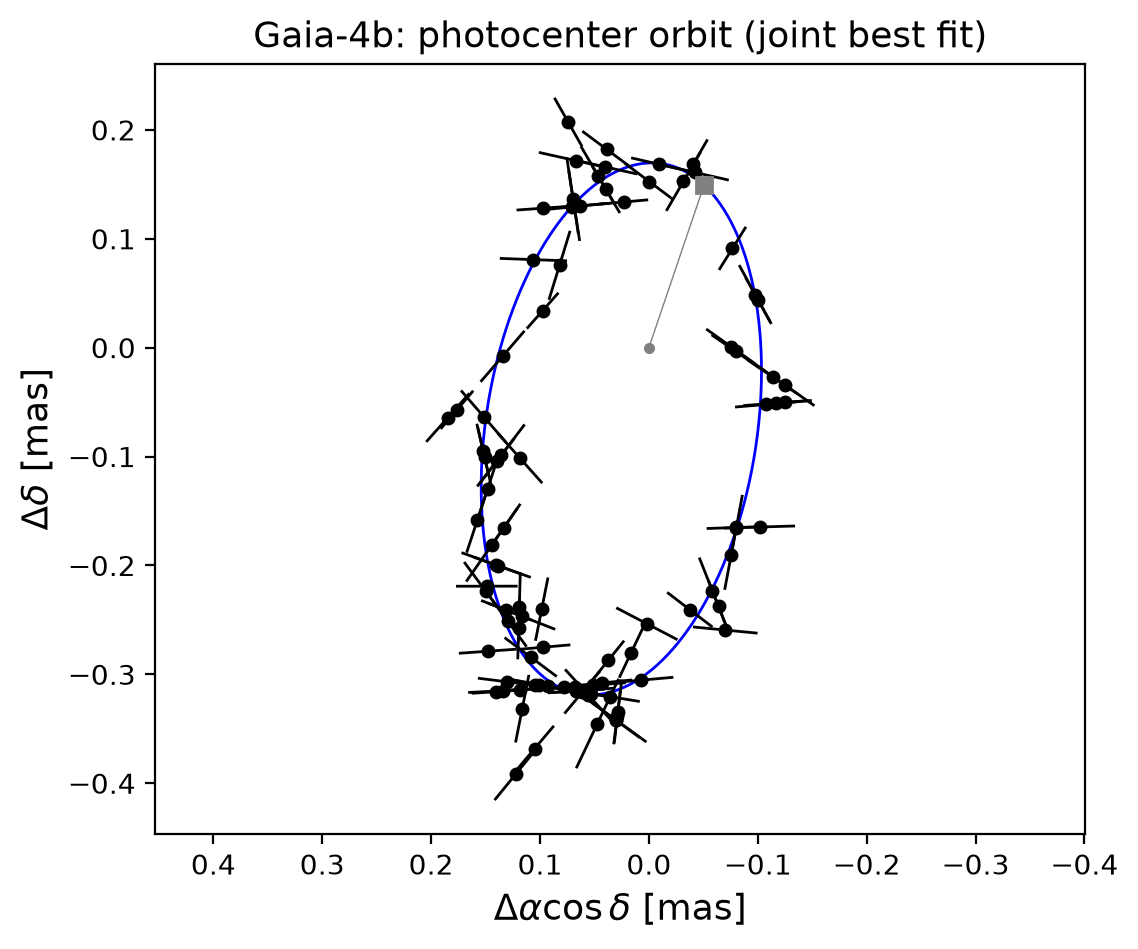

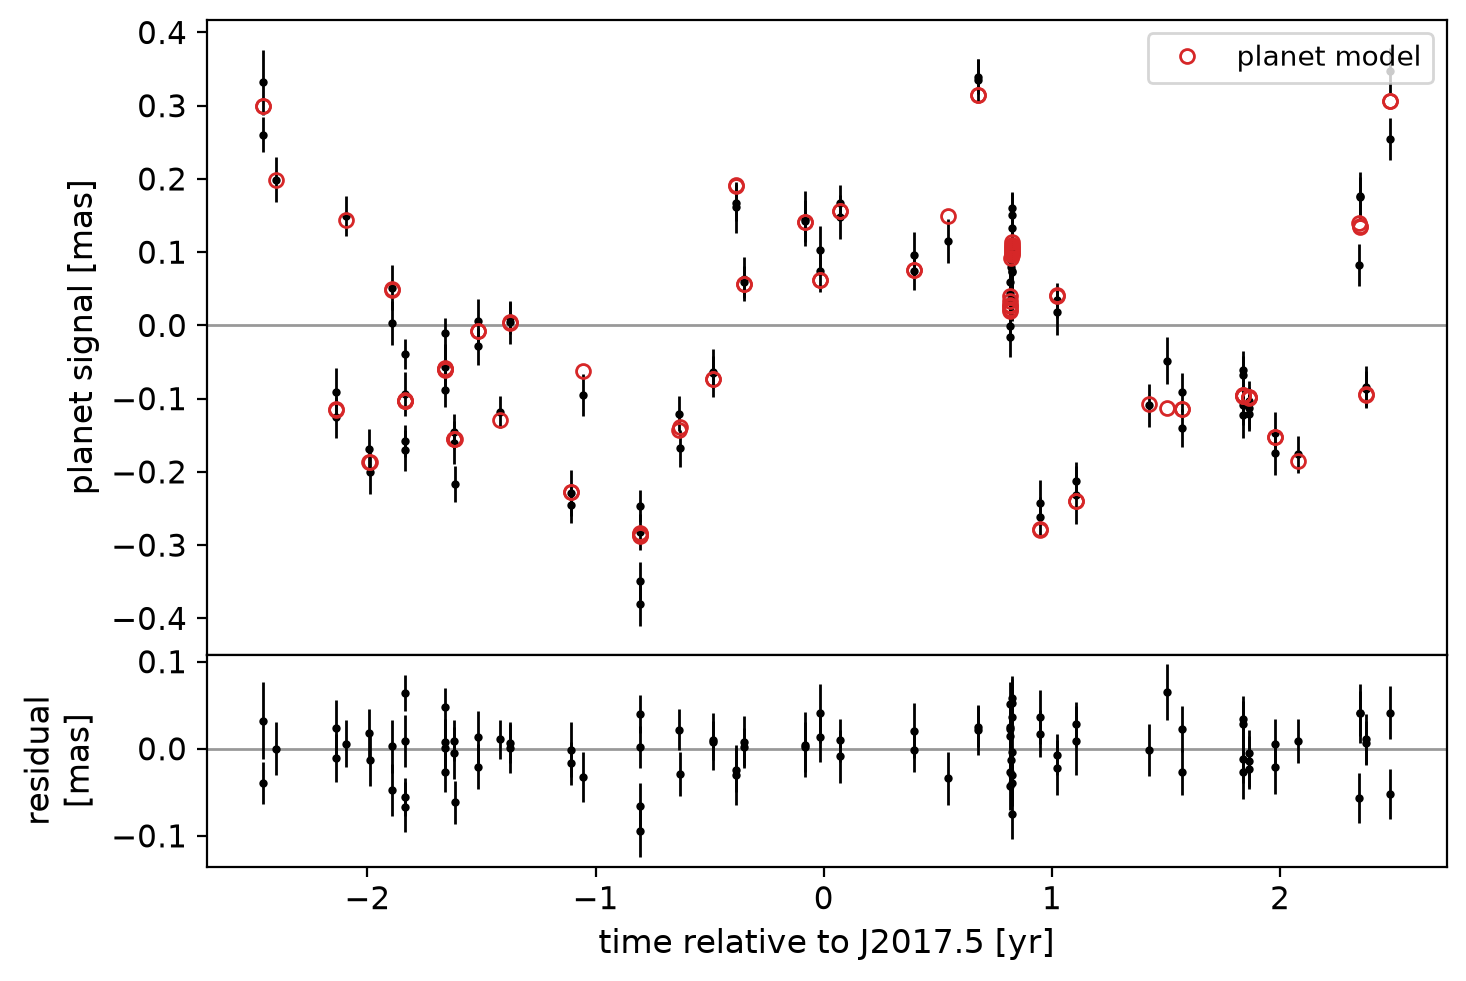

In [7]:
A, B, F, G = gmp.get_thiele_innes(fit['a0_mas'], fit['Omega'], fit['inc'], fit['w'])
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*ast_data, period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'],
                                     delta_ra=res['ra_off'], delta_dec=res['dec_off'], parallax=res['parallax'],
                                     pmra=res['pmra'], pmdec=res['pmdec'], A=A, B=B, F=F, G=G,
                                     data_release='dr4', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Gaia-4b: photocenter orbit (joint best fit)', fontsize=13)
plt.show()

model, components = gmp.astrometry_planets_model(t_ast_yr, psi, plx_factor, res['ra_off'], res['dec_off'], res['parallax'],
                                                 res['pmra'], res['pmdec'], m_star, res['model_planets'], c_funcs,
                                                 return_components=True)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
axes[0].errorbar(t_ast_yr, ast_obs - (model - components[0]), ast_err, fmt='k.', ms=4, lw=1, zorder=1)
axes[0].plot(t_ast_yr, components[0], 'o', mfc='none', mec='C3', ms=5, zorder=2, label='planet model')
axes[0].set_ylabel('planet signal [mas]', fontsize=12)
axes[0].legend(loc='upper right', fontsize=10)
axes[1].errorbar(t_ast_yr, ast_obs - model, ast_err, fmt='k.', ms=4, lw=1)
axes[1].set_ylabel('residual\n[mas]', fontsize=12)
axes[1].set_xlabel('time relative to J2017.5 [yr]', fontsize=12)
for ax in axes:
    ax.axhline(0, color='0.6', lw=1, zorder=0)
    ax.tick_params(labelsize=11)
plt.show()

The RVs, with each instrument's systemic velocity subtracted (error bars: formal uncertainty and fitted jitter in quadrature), the best-fit RV curve, and the residuals (as in notebook 03). The RVs were taken 6 to 8.5 yr after J2017.5, after the DR4 astrometry.

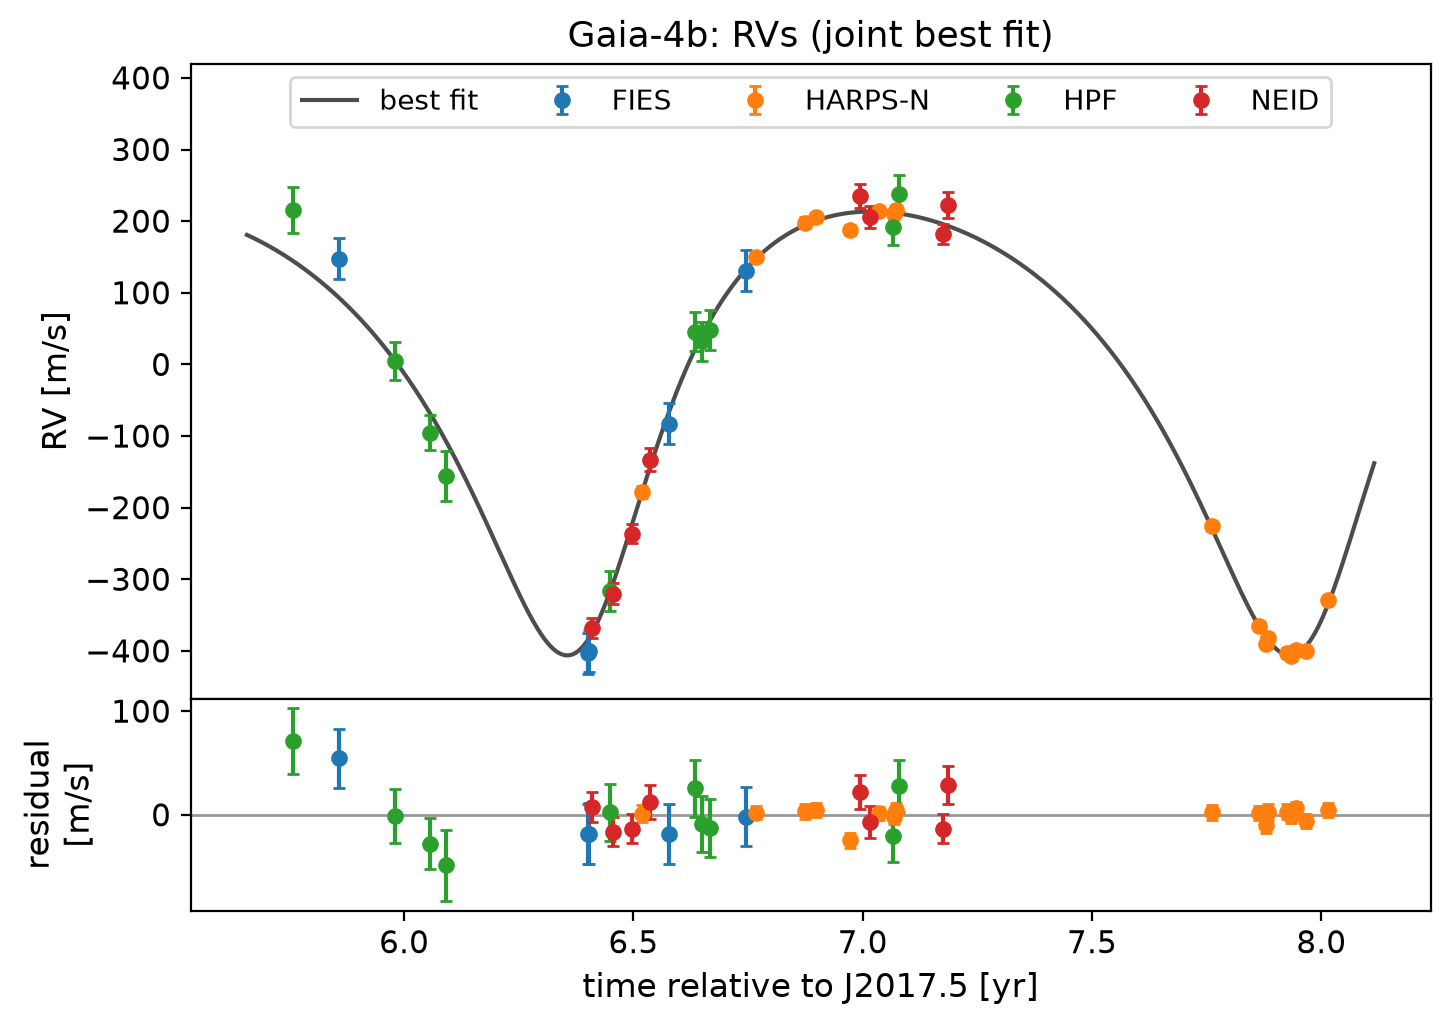

In [8]:
t_grid = np.linspace(t_rvs_yr.min() - 0.1, t_rvs_yr.max() + 0.1, 2000)
curve = gmp.rv_planets_model(t_grid, m_star, res['model_planets'], 0.0, c_funcs)
rv_model = gmp.rv_planets_model(t_rvs_yr, m_star, res['model_planets'], res['gamma'], c_funcs, rv_dataset=rv_dataset)
err = np.sqrt(rv_err**2 + res['jitter'][rv_dataset]**2)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
axes[0].plot(t_grid, 1e3*curve, color='0.3', lw=1.5, zorder=0, label='best fit')
for k, name in enumerate(instruments):
    on = rv_dataset == k
    axes[0].errorbar(t_rvs_yr[on], 1e3*(rv[on] - res['gamma'][k]), 1e3*err[on], fmt='o', ms=5, capsize=2, label=name)
    axes[1].errorbar(t_rvs_yr[on], 1e3*(rv[on] - rv_model[on]), 1e3*err[on], fmt='o', ms=5, capsize=2)
axes[1].axhline(0, color='0.6', lw=1, zorder=0)
axes[0].set_ylabel('RV [m/s]', fontsize=12)
axes[1].set_ylabel('residual\n[m/s]', fontsize=12)
axes[1].set_xlabel('time relative to J2017.5 [yr]', fontsize=12)
axes[0].set_title('Gaia-4b: RVs (joint best fit)', fontsize=13)
axes[0].set_ylim(top=420)
axes[0].legend(fontsize=10, ncol=5, loc='upper center')
for ax in axes:
    ax.tick_params(labelsize=11)
plt.show()

## 5. MCMC

As in notebook 03, `log_likelihood_astrometry_and_rv_planets` integrates out the position offsets, proper motion and systemic velocities, so the walkers sample the parallax and the planet's orbit, followed by the jitter of each RV dataset and an astrometric jitter $s$ (`fit_ast_jitter=True`), started at the value that makes the best fit's astrometric reduced $\chi^2$ 1; `expand_marginal_samples` then draws the integrated-out parameters of each sample. The priors are uniform, with $0 \le i \le \pi$, $a_0 > 0$, $\phi_p$, $\Omega$ and $\omega$ within $\pi$ of their best-fit values (as in notebook 01), RV jitters below 200 m/s and $s$ below 0.5 mas.

In [9]:
names = gmp.sampled_names(res) + [f'jitter_{name}' for name in instruments] + ['ast_jitter']
print(names)

best = dict(zip(res['theta_names'], res['theta']))  # best-fit values by name
angles0 = np.array([best['phi_p_0'], best['Omega_0'], best['w_0']])

def log_prior(theta):
    plx, P, e, inc, a0, jit, s = theta[0], theta[1], theta[2], theta[5], theta[7], theta[8:12], theta[12]
    angles = theta[[3, 4, 6]]  # phi_p, Omega, w
    if (0 < plx and 10 < P < 1e4 and 0 <= e < 1 and 0 <= inc <= np.pi and 0 < a0 and np.all(np.abs(angles - angles0) < np.pi)
            and np.all((0 <= jit) & (jit < 0.2)) and 0 <= s < 0.5):
        return 0.0
    return -np.inf

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_and_rv_planets(theta, *ast_data, *rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 48, 30000
p0 = gmp.initial_walkers(res, nwalkers, log_prob=log_prior, ast_jitter=s0, rng=rng)
np.random.seed(1)  # emcee draws its moves from numpy's global random state
sampler = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob)
sampler.run_mcmc(p0, nsteps, progress=True);

['parallax', 'period_0', 'ecc_0', 'phi_p_0', 'Omega_0', 'inc_0', 'w_0', 'a0_mas_0', 'jitter_FIES', 'jitter_HARPS-N', 'jitter_HPF', 'jitter_NEID', 'ast_jitter']
starting astrometric jitter: 23.1 microarcsec


In [10]:
# convergence: the chain should be much longer than the autocorrelation time (tol=0: estimate it whatever the chain length)
tau = sampler.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)  # discard the burn-in (5 autocorrelation times) and thin the chain
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples)} samples')
samples = gmp.expand_marginal_samples(samples, res, ast_data=ast_data, rv_data=rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True,
                                      rng=rng)  # all parameters, ordered like res['theta'], then the jitters

autocorrelation times [steps]: parallax 192, period_0 170, ecc_0 188, phi_p_0 171, Omega_0 181, inc_0 187, w_0 173, a0_mas_0 183, jitter_FIES 291, jitter_HARPS-N 200, jitter_HPF 232, jitter_NEID 218, ast_jitter 176
chain length / longest autocorrelation time = 103
9408 samples


## 6. Corner plot

The planet mass is computed for each sample from $a_0$, $P$, $\varpi$ and the stellar mass, as in notebook 03.

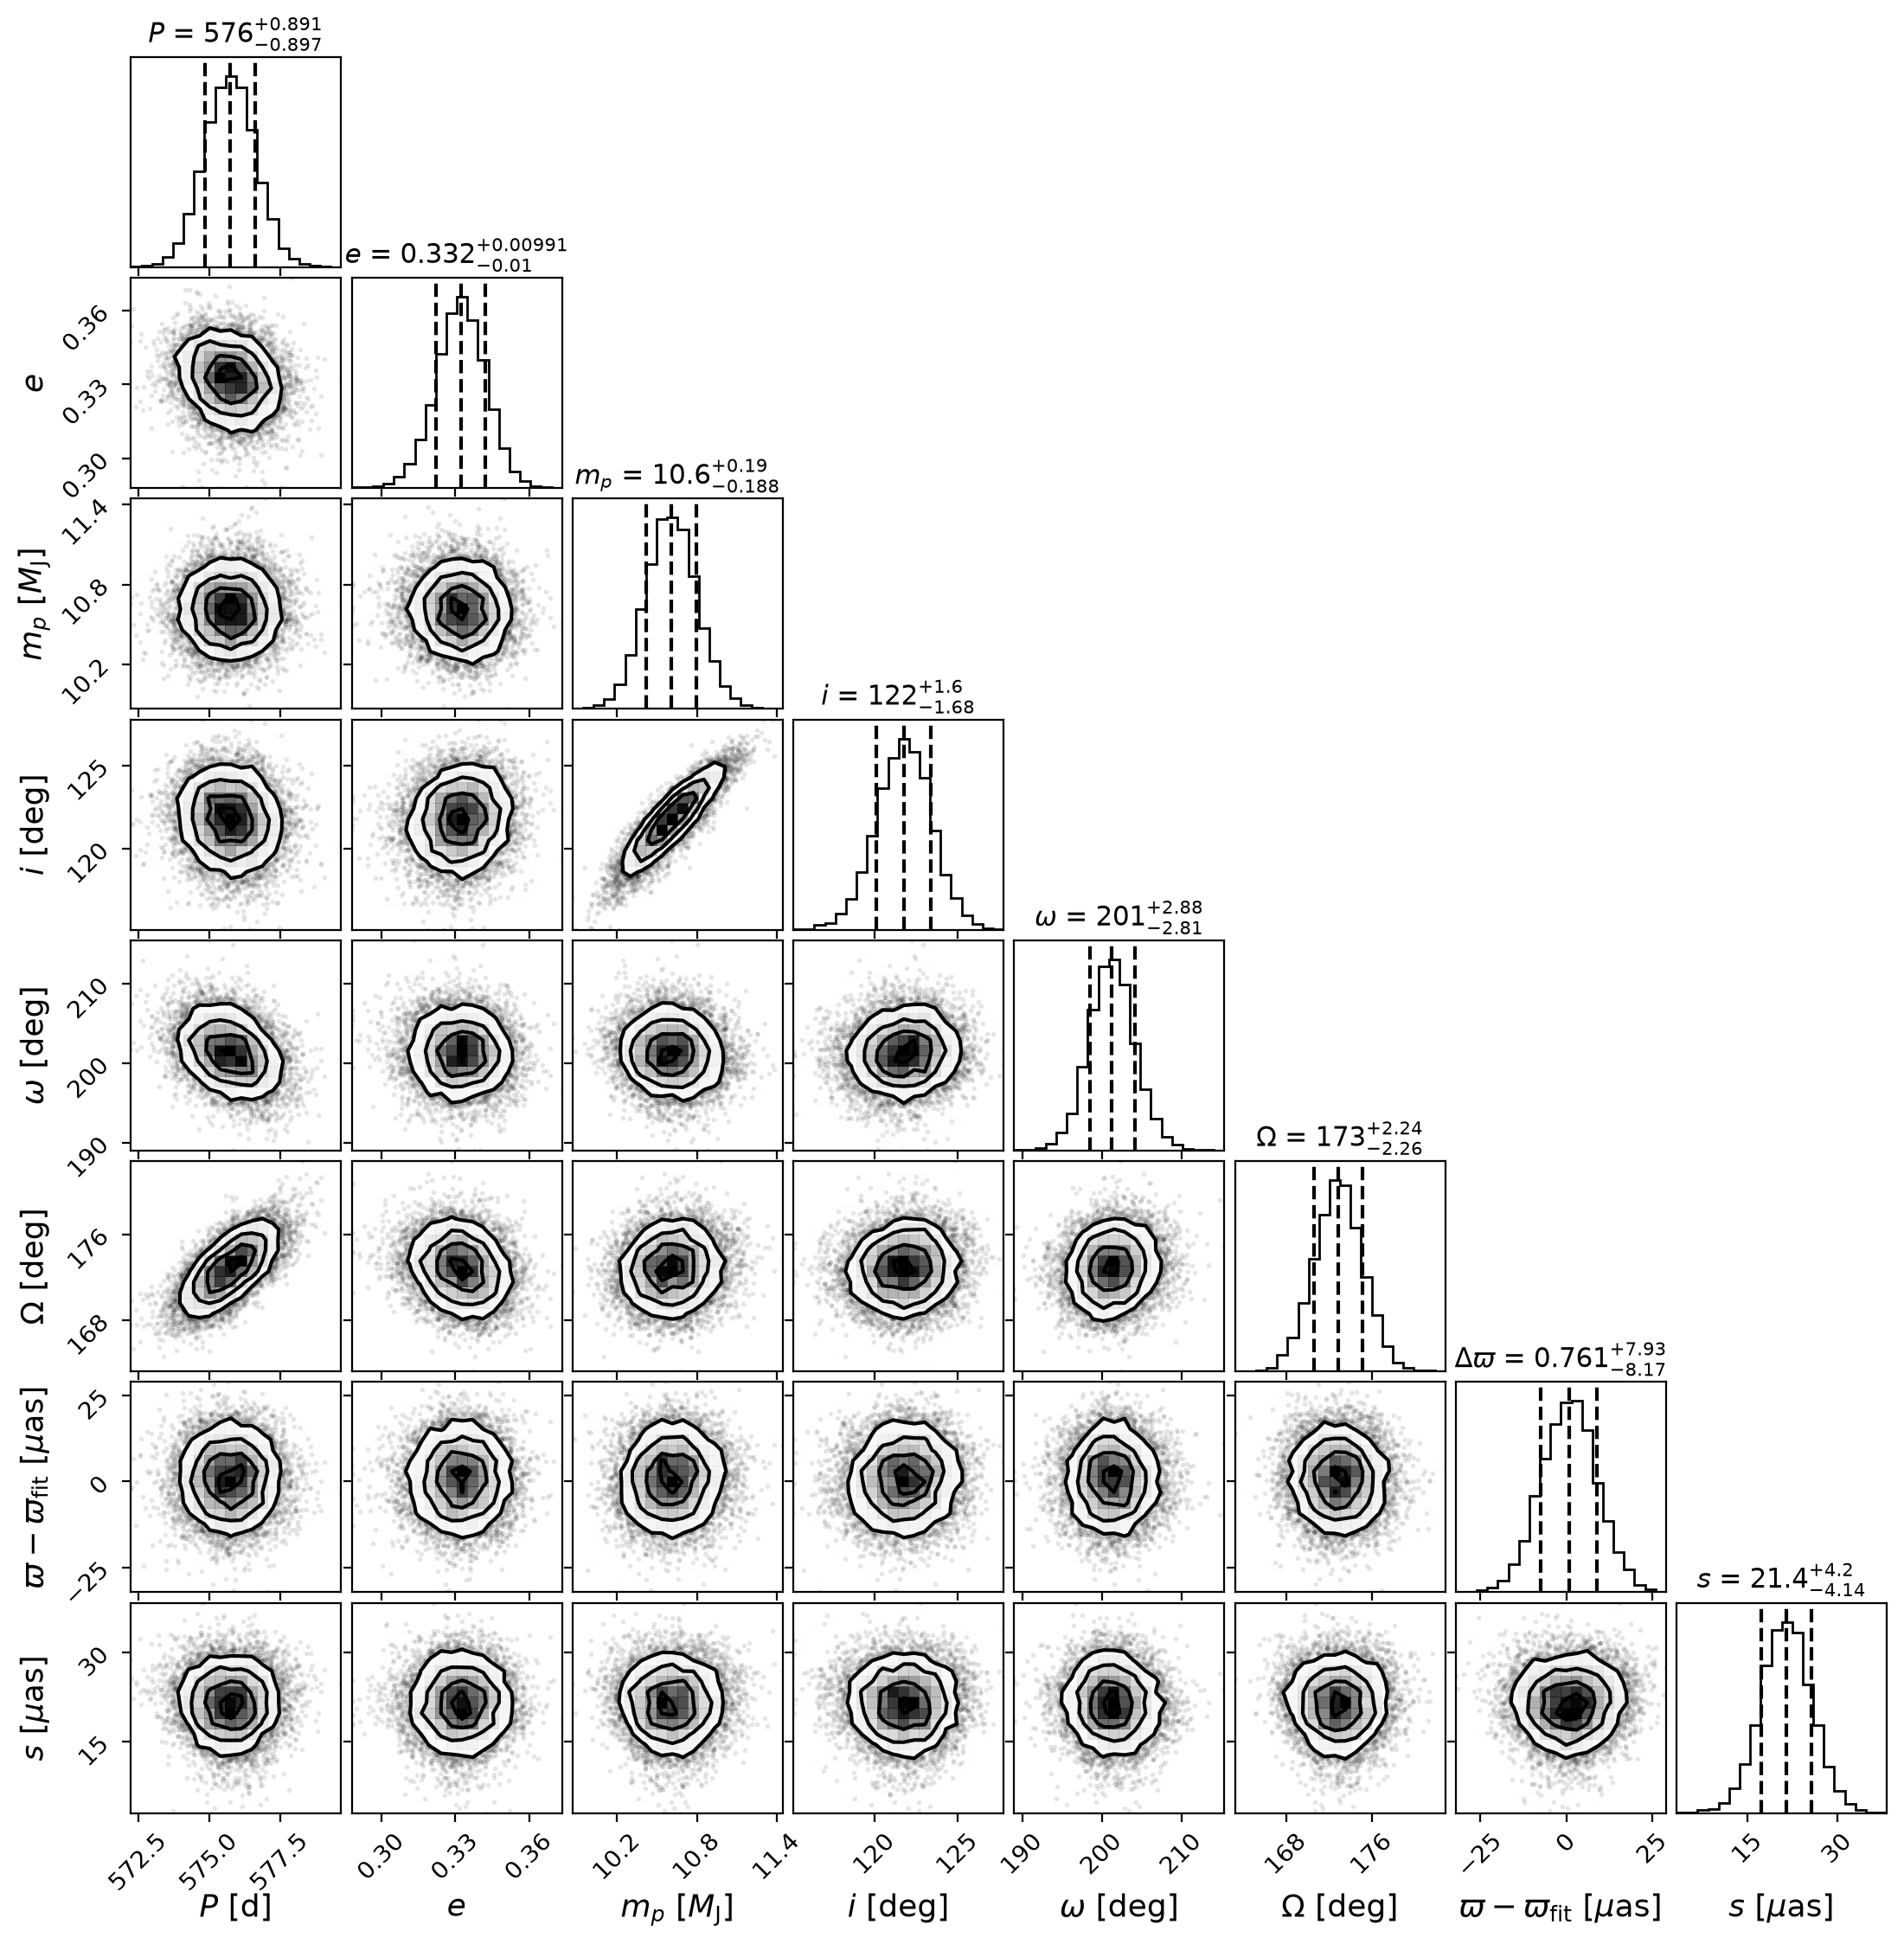

In [11]:
plx_s, P_s, e_s, phi_s, Omega_s, inc_s, w_s, a0_s = (samples[:, k] for k in (2, 5, 6, 7, 8, 9, 10, 11))
m_s = gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star)
w_s = fit['w'] + np.angle(np.exp(1j*(w_s - fit['w'])))              # keep the angles continuous around the best fit
Omega_s = fit['Omega'] + np.angle(np.exp(1j*(Omega_s - fit['Omega'])))

corner_samples = np.column_stack([P_s, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s), 1e3*(plx_s - res['parallax']),
                                  1e3*samples[:, -1]])
labels = [r'$P$ [d]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]', r'$\varpi - \varpi_\mathrm{fit}$ [$\mu$as]', r'$s$ [$\mu$as]']
titles = [r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$\Delta\varpi$', r'$s$']
fig = corner.corner(corner_samples, labels=labels, titles=titles, quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g',
                    max_n_ticks=3, labelpad=0.08, label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

In [12]:
# posterior summary: median and 68% interval
def summary(label, x, fmt='.3f'):
    lo, med, hi = np.percentile(x, [16, 50, 84])
    print(f'{label:22s} {med:{fmt}} (+{hi - med:{fmt}} / -{med - lo:{fmt}})')

for label, x in zip(['P [d]', 'e', 'm_p [M_Jup]', 'inc [deg]', 'w [deg]', 'Omega [deg]'], corner_samples.T):
    summary(label, x)
summary('parallax [mas]', plx_s, '.4f')
summary('Tp [d]', phi_s*P_s/(2*np.pi), '.1f')
summary('pmra [mas/yr]', samples[:, 3], '.4f')
summary('pmdec [mas/yr]', samples[:, 4], '.4f')
summary('ast_jitter [microarcsec]', 1e3*samples[:, -1], '.1f')
for k, name in enumerate(instruments):
    summary(f'gamma_{name} [m/s]', 1e3*samples[:, 12 + k], '.1f')
    summary(f'jitter_{name} [m/s]', 1e3*samples[:, 16 + k], '.1f')

P [d]                  575.736 (+0.891 / -0.897)
e                      0.332 (+0.010 / -0.010)
m_p [M_Jup]            10.605 (+0.190 / -0.188)
inc [deg]              121.770 (+1.601 / -1.675)
w [deg]                201.270 (+2.879 / -2.815)
Omega [deg]            172.861 (+2.245 / -2.259)
parallax [mas]         13.6261 (+0.0079 / -0.0082)
Tp [d]                 34.9 (+5.7 / -5.7)
pmra [mas/yr]          -75.5329 (+0.0040 / -0.0039)
pmdec [mas/yr]         17.9660 (+0.0039 / -0.0039)
ast_jitter [microarcsec] 21.4 (+4.2 / -4.1)
gamma_FIES [m/s]       -2.4 (+19.2 / -20.3)
jitter_FIES [m/s]      39.4 (+29.1 / -15.0)
gamma_HARPS-N [m/s]    -1.6 (+3.5 / -3.8)
jitter_HARPS-N [m/s]   8.0 (+2.4 / -1.8)
gamma_HPF [m/s]        -0.1 (+10.6 / -10.2)
jitter_HPF [m/s]       28.3 (+12.7 / -9.3)
gamma_NEID [m/s]       -2.8 (+7.8 / -7.3)
jitter_NEID [m/s]      16.4 (+8.9 / -5.8)
